<a href="https://colab.research.google.com/github/choudhary-hema/100-Next-Gen-AI-Engineer/blob/main/LoanApprovalPredicationPrac1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
# import dependencies
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as mpl

In [2]:
# load and read data
data=pd.read_csv("/content/LoanApprovalPrediction.csv")

In [5]:
# show case first 5 records
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
#showcasing the first 20 records
data.head(20)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2.0,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0.0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3.0,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2.0,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1.0,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [8]:
#Number of approved and rejected applications
data['Loan_Status'].value_counts()

,count
Loan_Status,
Y,411
N,187


In [9]:
#number of married and unmarried customers
data['Married'].value_counts()

,count
Married,
Yes,388
No,210


In [10]:
data.describe()

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,586.000000,598.000000,598.000000,577.000000,584.000000,549.000000
mean,0.755973,5292.252508,1631.499866,144.968804,341.917808,0.843352
std,1.007751,5807.265364,2953.315785,82.704182,65.205994,0.363800
min,0.000000,150.000000,0.000000,9.000000,12.000000,0.000000
25%,0.000000,2877.500000,0.000000,100.000000,360.000000,1.000000
50%,0.000000,3806.000000,1211.500000,127.000000,360.000000,1.000000
75%,1.750000,5746.000000,2324.000000,167.000000,360.000000,1.000000
max,3.000000,81000.000000,41667.000000,650.000000,480.000000,1.000000


In [11]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [12]:
data['Gender'].unique()

array(['Male', 'Female'], dtype=object)

In [13]:
data['Gender']=le.fit_transform(data['Gender'])

In [14]:
data['Gender'].unique()

array([1, 0])

In [15]:
data['Property_Area'].unique()

array(['Urban', 'Rural', 'Semiurban'], dtype=object)

In [16]:
data['Property_Area'] = le.fit_transform(data['Property_Area'])

In [17]:
data['Property_Area'].unique()

array([2, 0, 1])

In [18]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,2,Y
1,LP001003,1,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,0,N
2,LP001005,1,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,2,Y
3,LP001006,1,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,2,Y
4,LP001008,1,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,2,Y


In [19]:
data=data.drop(['ApplicantIncome'],axis=1)

In [22]:
data=data.drop(['CoapplicantIncome'],axis=1)

In [23]:
new_data=data

In [24]:
new_data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1,No,0.0,Graduate,No,NaN,360.0,1.0,2,Y
1,LP001003,1,Yes,1.0,Graduate,No,128.0,360.0,1.0,0,N
2,LP001005,1,Yes,0.0,Graduate,Yes,66.0,360.0,1.0,2,Y
3,LP001006,1,Yes,0.0,Not Graduate,No,120.0,360.0,1.0,2,Y
4,LP001008,1,No,0.0,Graduate,No,141.0,360.0,1.0,2,Y


In [25]:
approved=(new_data['Loan_Status']=='Y').sum()

In [26]:
rejected=(new_data['Loan_Status']=='N').sum()

In [27]:
labels=['Approved','Rejected']
values=[approved,rejected]

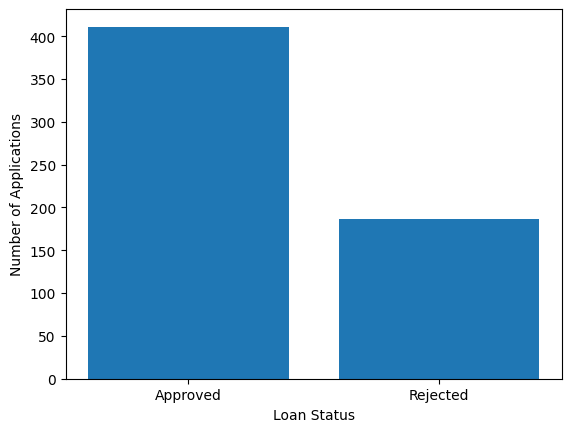

In [38]:
mpl.bar(labels, values)
mpl.xlabel("Loan Status")
mpl.ylabel("Number of Applications")
mpl.show()

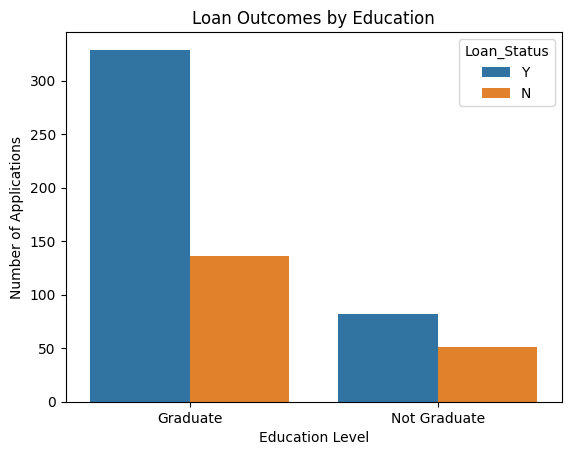

In [35]:
sb.countplot(data,x='Education',hue='Loan_Status')
plt.title("Loan Outcomes by Education")
plt.xlabel("Education Level")
plt.ylabel("Number of Applications")

plt.show()

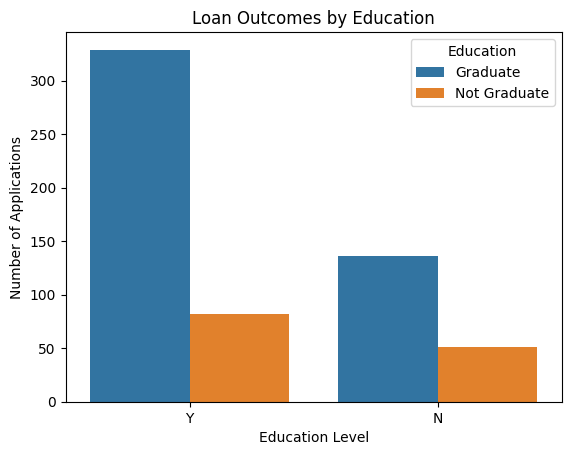

In [39]:
sb.countplot(data,x='Loan_Status',hue='Education')
plt.title("Loan Outcomes by Education")
plt.xlabel("Education Level")
plt.ylabel("Number of Applications")

plt.show()

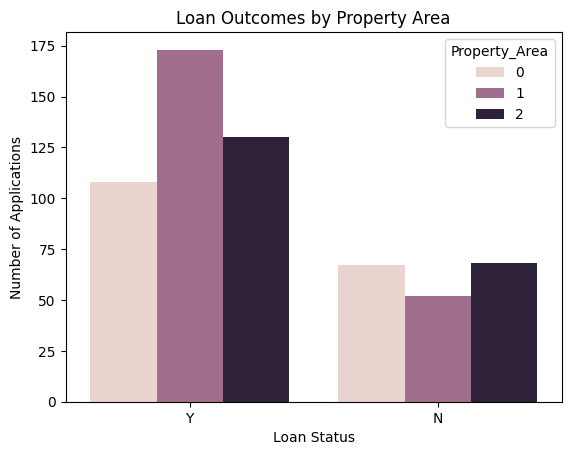

In [41]:
sb.countplot(data,x='Loan_Status',hue='Property_Area')
plt.title("Loan Outcomes by Property Area")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")

plt.show()

In [42]:
status_counts=data['Loan_Status'].value_counts()

In [43]:
status_counts

,count
Loan_Status,
Y,411
N,187


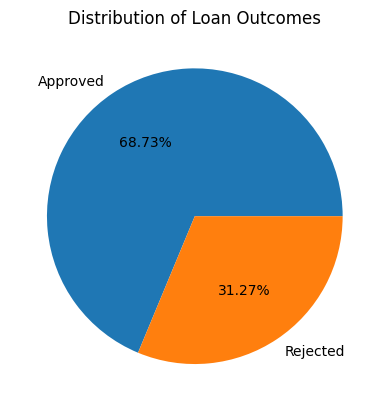

In [44]:
plt.pie(status_counts.values,labels=['Approved' if x=='Y' else 'Rejected'
for x in status_counts.index], autopct='%.2f%%')

plt.title("Distribution of Loan Outcomes")
plt.show()

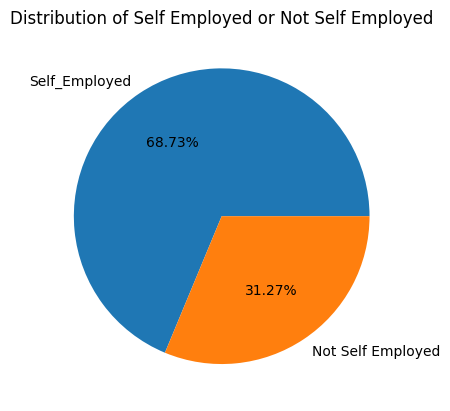

In [46]:
plt.pie(status_counts.values,labels=['Self_Employed' if x=='Y' else 'Not Self Employed'
for x in status_counts.index], autopct='%.2f%%')

plt.title("Distribution of Self Employed or Not Self Employed")
plt.show()